<a href="https://colab.research.google.com/github/JohnJomi/Retail-Sales-Prediction-Model-/blob/Dev/Untitled8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import glob
import pandas as pd

# Install kagglehub tool to easily fetch public datasets without needing api tokens
!pip install -q kagglehub
import kagglehub

# Download the Retail Sales Dataset
dataset_path = kagglehub.dataset_download("mohammadtalib786/retail-sales-dataset")
print("Downloaded dataset directory:", dataset_path)

# Discover all CSV files in the downloaded path
csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)
print("CSV files discovered:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV files found in the downloaded dataset directory.")

# Load the primary dataset
df = pd.read_csv(csv_files[0])
print("\nDataset loaded successfully!")

Using Colab cache for faster access to the 'retail-sales-dataset' dataset.
Downloaded dataset directory: /kaggle/input/retail-sales-dataset
CSV files discovered: ['/kaggle/input/retail-sales-dataset/retail_sales_dataset.csv']

Dataset loaded successfully!


In [11]:
# Inspect the dataset metadata
print("=== Dataset Shape ===")
print(df.shape)

print("\n=== Column Data Types ===")
print(df.dtypes)

print("\n=== First 5 Records ===")
display(df.head())

=== Dataset Shape ===
(1000, 14)

=== Column Data Types ===
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
Year                         int32
Month                        int32
Day                          int32
Weekday                     object
Age Group                 category
dtype: object

=== First 5 Records ===


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Year,Month,Day,Weekday,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11,24,Friday,25-40
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2,27,Monday,25-40
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1,13,Friday,41-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5,21,Sunday,25-40
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5,6,Saturday,25-40


In [12]:
print("=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())

# Convert Date to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Feature Engineering: Extracting datetime features
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Weekday'] = df['Date'].dt.day_name()

# Describe numerical variables to identify potential inconsistencies
print("\n=== Descriptive Statistics ===")
display(df.describe())

print("\n=== Cleaned Dataset Sample ===")
display(df.head())

=== Missing Values ===
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Year                0
Month               0
Day                 0
Weekday             0
Age Group           0
dtype: int64

=== Duplicate Rows ===
0

=== Descriptive Statistics ===


,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount,Year,Month,Day
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000,2023.002000,6.549000,15.310000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000,2023.000000,1.000000,1.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000,2023.000000,4.000000,7.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000,2023.000000,6.000000,15.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000,2023.000000,10.000000,23.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000,2024.000000,12.000000,31.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632,0.044699,3.452755,8.871674



=== Cleaned Dataset Sample ===


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Year,Month,Day,Weekday,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11,24,Friday,25-40
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2,27,Monday,25-40
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1,13,Friday,41-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5,21,Sunday,25-40
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5,6,Saturday,25-40


/tmp/ipykernel_5889/1467556106.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Product Category', y='Total Amount', estimator=sum, errorbar=None, ax=axes[0,0], palette='viridis')
/tmp/ipykernel_5889/1467556106.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Gender', y='Total Amount', estimator=sum, errorbar=None, ax=axes[0,1], palette='pastel')
/tmp/ipykernel_5889/1467556106.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Age Group', y='Total Amount', estimator=sum, errorbar=None, ax=axes[1,0

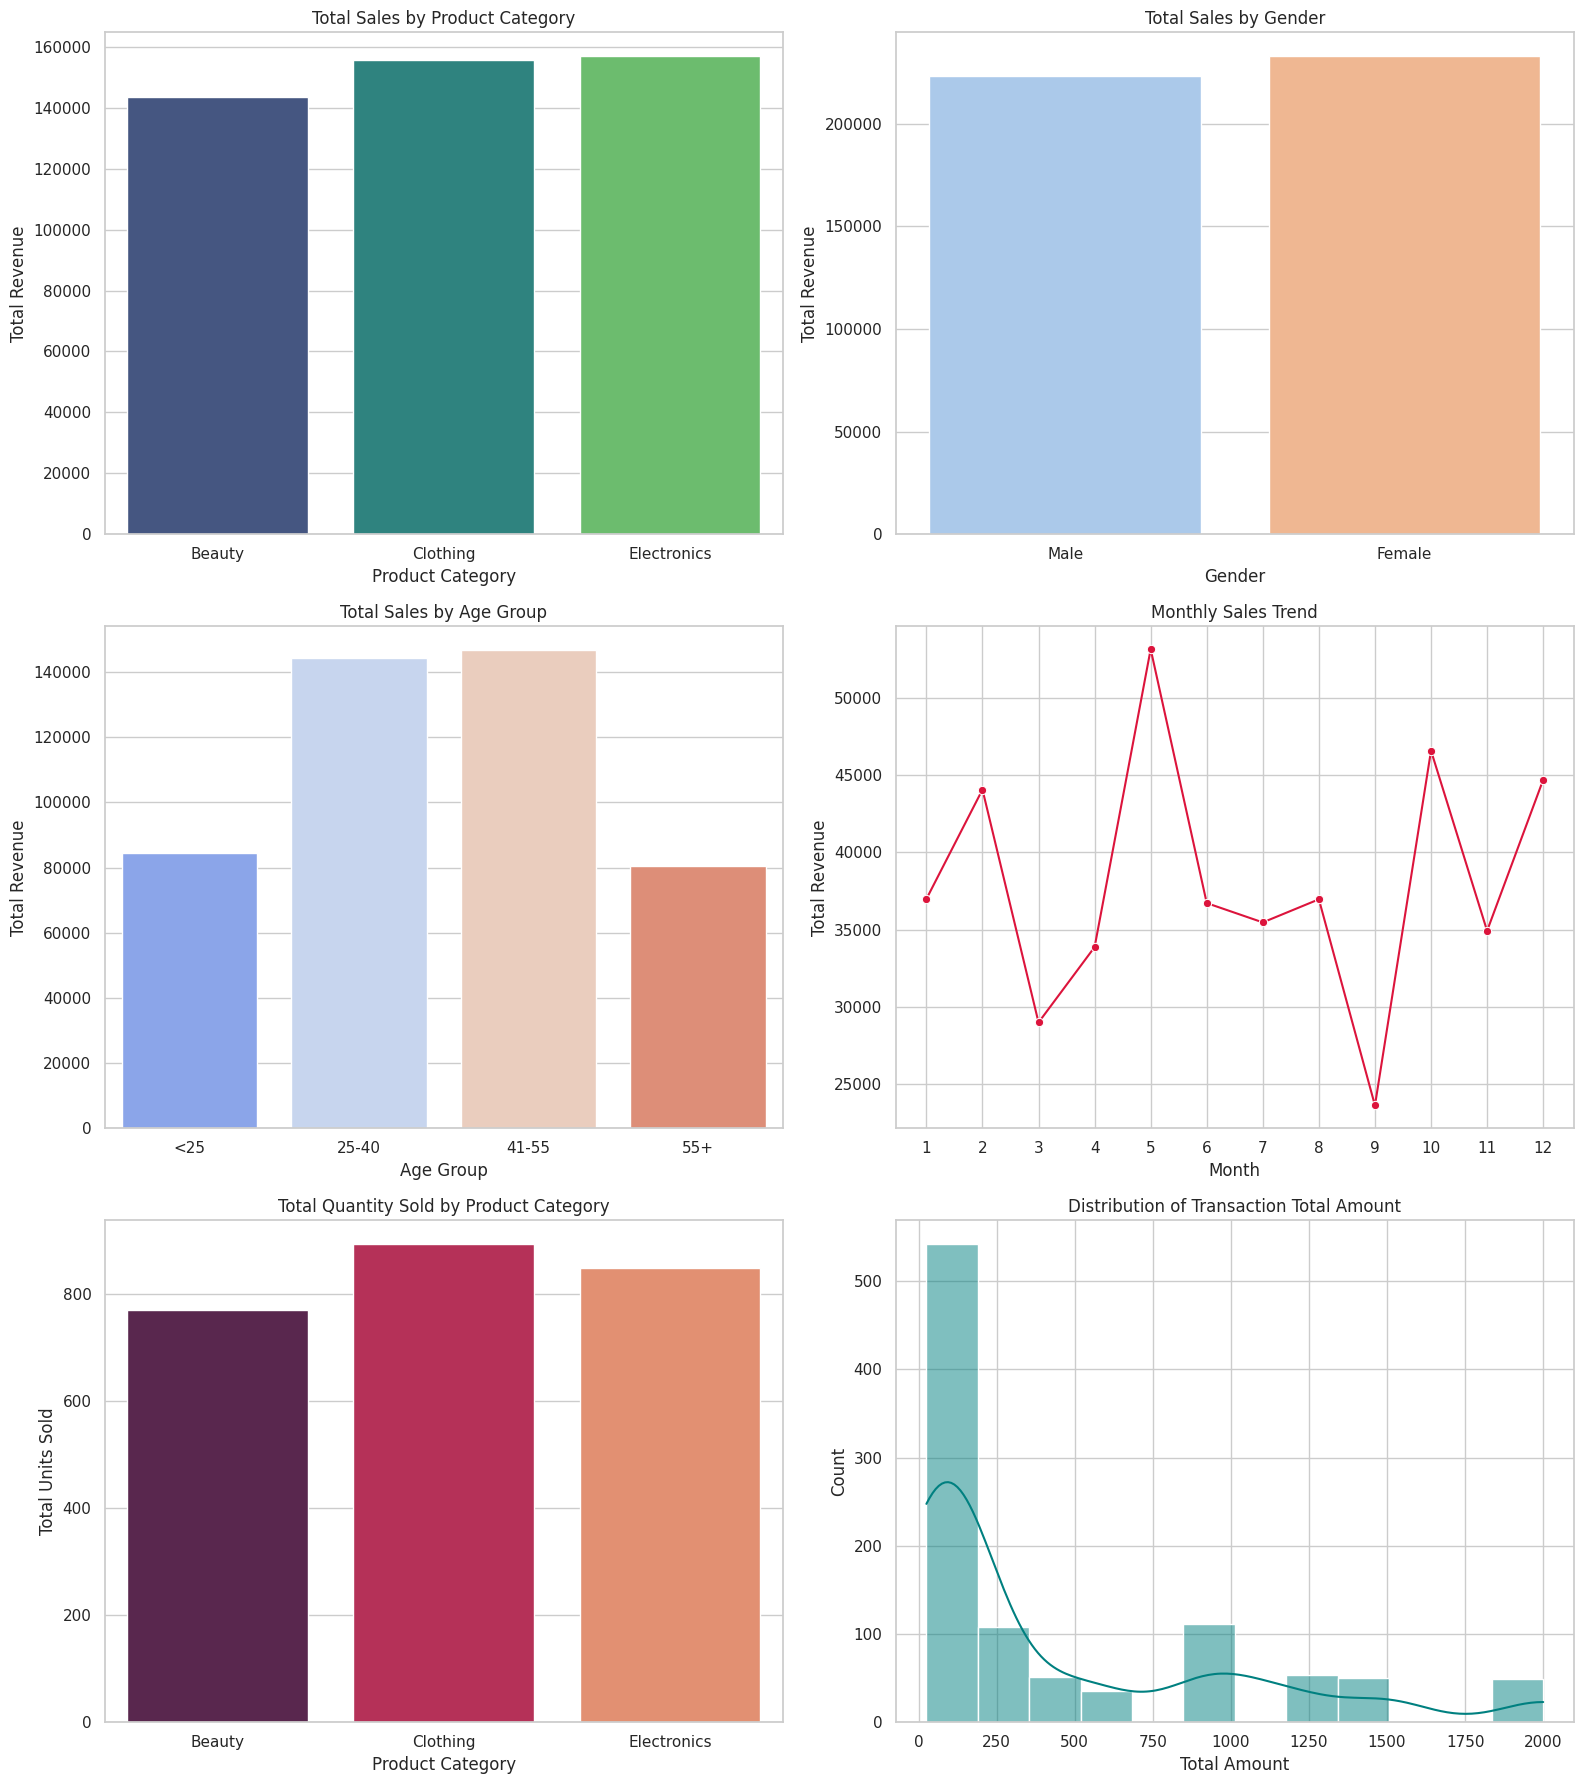

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Sales (Total Amount) by Product Category
sns.barplot(data=df, x='Product Category', y='Total Amount', estimator=sum, errorbar=None, ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Total Sales by Product Category')
axes[0,0].set_ylabel('Total Revenue')

# 2. Sales by Gender
sns.barplot(data=df, x='Gender', y='Total Amount', estimator=sum, errorbar=None, ax=axes[0,1], palette='pastel')
axes[0,1].set_title('Total Sales by Gender')
axes[0,1].set_ylabel('Total Revenue')

# 3. Sales by Age Group
df['Age Group'] = pd.cut(df['Age'], bins=[0, 25, 40, 55, 100], labels=['<25', '25-40', '41-55', '55+'])
sns.barplot(data=df, x='Age Group', y='Total Amount', estimator=sum, errorbar=None, ax=axes[1,0], palette='coolwarm')
axes[1,0].set_title('Total Sales by Age Group')
axes[1,0].set_ylabel('Total Revenue')

# 4. Monthly Sales Trends
monthly_sales = df.groupby('Month')['Total Amount'].sum().reset_index()
sns.lineplot(data=monthly_sales, x='Month', y='Total Amount', marker='o', ax=axes[1,1], color='crimson')
axes[1,1].set_title('Monthly Sales Trend')
axes[1,1].set_ylabel('Total Revenue')
axes[1,1].set_xticks(range(1, 13))

# 5. Quantity Sold by Product Category
sns.barplot(data=df, x='Product Category', y='Quantity', estimator=sum, errorbar=None, ax=axes[2,0], palette='rocket')
axes[2,0].set_title('Total Quantity Sold by Product Category')
axes[2,0].set_ylabel('Total Units Sold')

# 6. Revenue Distribution
sns.histplot(data=df, x='Total Amount', kde=True, ax=axes[2,1], color='teal')
axes[2,1].set_title('Distribution of Transaction Total Amount')

plt.tight_layout()
plt.show()

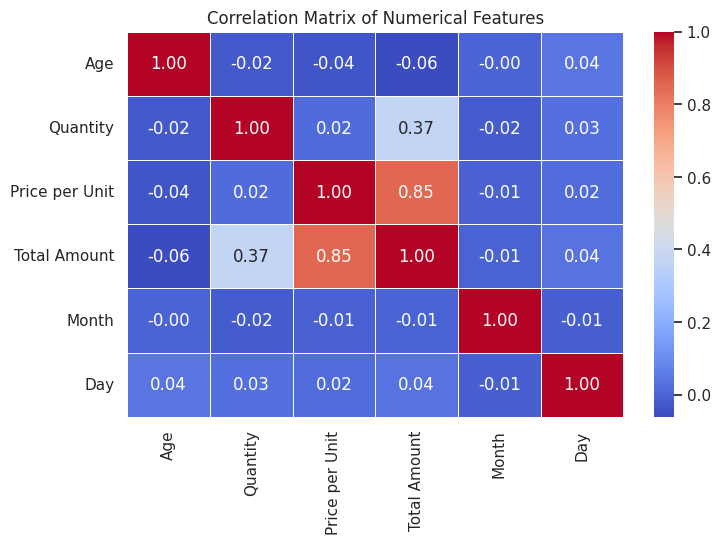

In [7]:
# 7. Correlation Heatmap
plt.figure(figsize=(8, 5))
corr = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount', 'Month', 'Day']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## Stage 4: Model Building

We will build a **Random Forest Regressor** to predict transaction-level `Total Amount`.

### Critical Discussion on Inputs:
In this dataset, `Total Amount` is mathematically calculated as:
$$\text{Total Amount} = \text{Quantity} \times \text{Price per Unit}$$
To make our machine learning problem challenging and realistic, we **must exclude** `Quantity` and `Price per Unit` from our feature space. If we included them, the model would simply learn standard arithmetic instead of meaningful historical consumer/product patterns. Instead, we use features like customer demographic details and product characteristics to predict the expected transaction size.

### Features Used:
- `Age`
- `Gender`
- `Product Category`
- `Month`
- `Day`

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Define Independent and Dependent Variables
X = df[['Age', 'Gender', 'Product Category', 'Month', 'Day']]
y = df['Total Amount']

# Split into Train and Test subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Setup preprocessing with pipeline and encoder
categorical_features = ['Gender', 'Product Category']
numerical_features = ['Age', 'Month', 'Day']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ], remainder='passthrough'
)

# Create full training pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train model
model_pipeline.fit(X_train, y_train)
print("Random Forest Regressor pipeline trained successfully!")

Random Forest Regressor pipeline trained successfully!


## Stage 5: Model Evaluation

Let's evaluate the predictions using standard performance metrics:
- **Mean Absolute Error (MAE)**
- **Mean Squared Error (MSE)**
- **Root Mean Squared Error (RMSE)**
- **R² Score**

=== Model Metrics ===
Mean Absolute Error (MAE): $476.11
Mean Squared Error (MSE): 335971.59
Root Mean Squared Error (RMSE): $579.63
R² Score: -0.1477


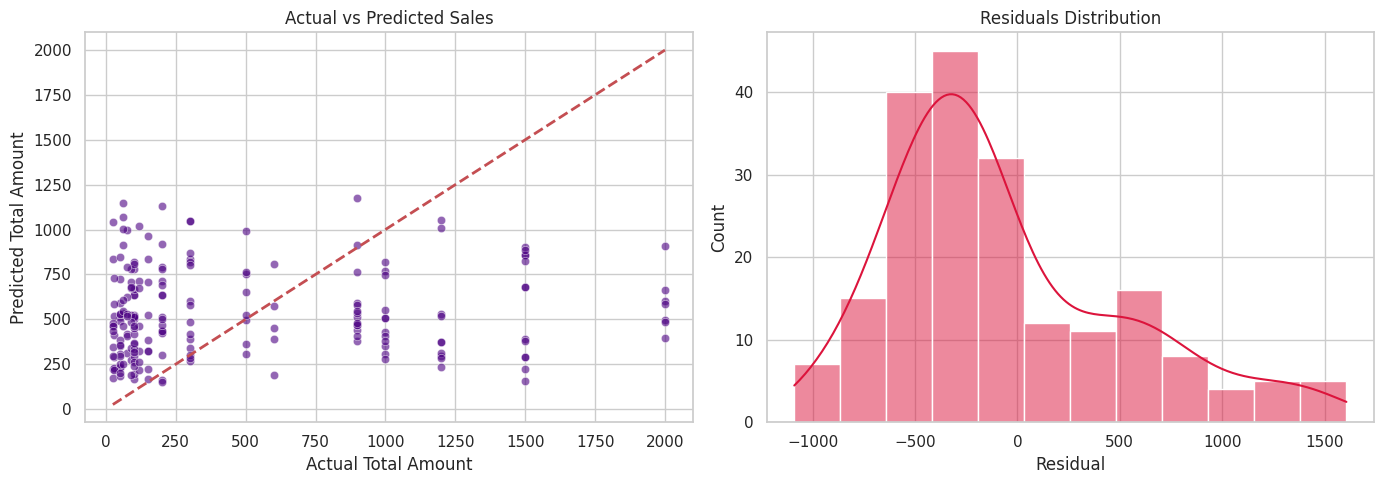

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Run predictions
y_pred = model_pipeline.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"=== Model Metrics ===")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# Diagnostics Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted Scatterplot
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, ax=axes[0], color='indigo')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs Predicted Sales')
axes[0].set_xlabel('Actual Total Amount')
axes[0].set_ylabel('Predicted Total Amount')

# 2. Residual Distribution Plot
residuals = y_test - y_pred
sns.histplot(residuals, kde=True, ax=axes[1], color='crimson')
axes[1].set_title('Residuals Distribution')
axes[1].set_xlabel('Residual')

plt.tight_layout()
plt.show()

## Stage 6: Model Deployment

We will save the model with Joblib and deploy an interactive user interface inside this Google Colab session using **Gradio**.

In [10]:
!pip install -q gradio
import joblib
import gradio as gr

# Save the Pipeline artifact
joblib.dump(model_pipeline, 'retail_sales_pipeline.joblib')

# Loading the pipeline
loaded_pipeline = joblib.load('retail_sales_pipeline.joblib')

# Define user-facing predict function
def predict_transaction(age, gender, category, month, day):
    # Formulate inputs as a DataFrame matching pipeline structure
    input_data = pd.DataFrame({
        'Age': [age],
        'Gender': [gender],
        'Product Category': [category],
        'Month': [int(month)],
        'Day': [int(day)]
    })

    prediction = loaded_pipeline.predict(input_data)[0]
    return f"Predicted Transaction Amount: ${prediction:.2f}"

# Build Gradio UI
interface = gr.Interface(
    fn=predict_transaction,
    inputs=[
        gr.Slider(18, 100, value=30, step=1, label="Customer Age"),
        gr.Dropdown(["Male", "Female"], value="Female", label="Gender"),
        gr.Dropdown(list(df['Product Category'].unique()), value="Beauty", label="Product Category"),
        gr.Slider(1, 12, value=6, step=1, label="Month of Purchase"),
        gr.Slider(1, 31, value=15, step=1, label="Day of Month")
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Retail Sales Predictor",
    description="Enter customer and transaction details to predict the expected Total Amount of the transaction."
)

# Launch application
interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://89e6bb48f725fb1886.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
